# TV campaign delivery and replacement recovery

Investigate commitment-level delivery, station/daypart segments, due-date trends and campaign-start cohorts at one declared knowledge cutoff.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'tvads').exists(): ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from tvads.pipeline import current_output
OUT=current_output()
REPORTS=OUT/'reports'
summary=json.loads((REPORTS/'summary.json').read_text())
manifest=json.loads((OUT/'run_manifest.json').read_text())
fact=pd.read_parquet(OUT/'fact_commitments.parquet')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('Synthetic snapshot:',summary['as_of'])


Synthetic snapshot: 2026-07-15T00:00:00Z


In [2]:
due=fact[fact.due_commitment.eq(1)].copy()
pd.Series({k:summary[k] for k in ['total_commitments','cancelled_commitments','due_commitments','original_deliveries','makegood_recoveries','delivered_commitments','undelivered_mature_commitments','delivery_rate']})

total_commitments                 18000.000000
cancelled_commitments               562.000000
due_commitments                   17438.000000
original_deliveries               16080.000000
makegood_recoveries                 737.000000
delivered_commitments             16817.000000
undelivered_mature_commitments      621.000000
delivery_rate                         0.964388
dtype: float64

## Delivery composition

Original deliveries plus recovered commitments equal delivered units. Extra airings never create extra contracted units.

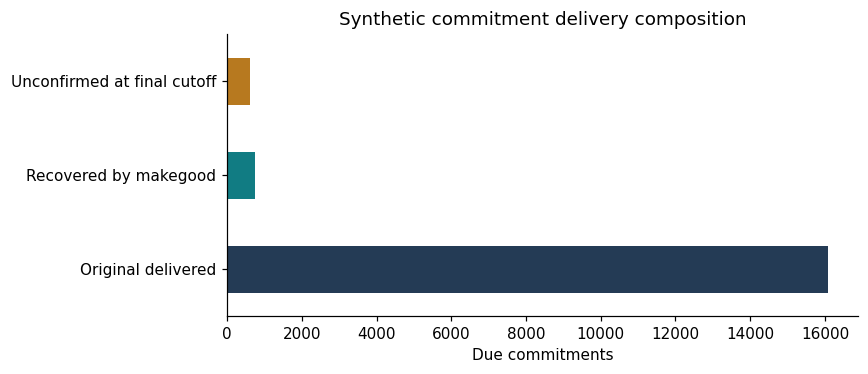

In [3]:
composition=pd.Series({'Original delivered':summary['original_deliveries'],'Recovered by makegood':summary['makegood_recoveries'],'Unconfirmed at final cutoff':summary['due_commitments']-summary['delivered_commitments']})
composition.plot.barh(figsize=(8,3.5),color=['#243B55','#117C83','#B7791F'])
plt.xlabel('Due commitments');plt.title('Synthetic commitment delivery composition');plt.tight_layout();plt.show()

In [4]:
by_part=due.groupby('daypart').agg(due_commitments=('commitment_id','size'),delivered=('delivered','sum'),original=('original_delivered','sum'),makegood_recovered=('delivery_status',lambda x:x.eq('makegood_delivered').sum()))
by_part['delivery_rate']=by_part.delivered/by_part.due_commitments
by_part['original_delivery_rate']=by_part.original/by_part.due_commitments
by_part

           due_commitments  delivered  ...  delivery_rate  original_delivery_rate
daypart                                ...                                       
Daytime               3592       3486  ...       0.970490                0.939031
Morning               4154       4041  ...       0.972797                0.944150
Overnight             4628       4377  ...       0.945765                0.869922
Prime                 5064       4913  ...       0.970182                0.939771

[4 rows x 6 columns]

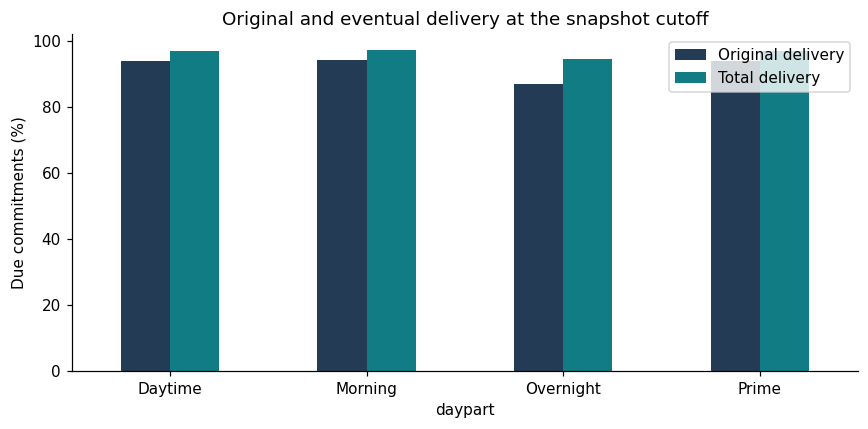

In [5]:
(by_part[['original_delivery_rate','delivery_rate']].rename(columns={'original_delivery_rate':'Original delivery','delivery_rate':'Total delivery'})*100).plot.bar(figsize=(8,4),color=['#243B55','#117C83'])
plt.ylabel('Due commitments (%)');plt.title('Original and eventual delivery at the snapshot cutoff');plt.xticks(rotation=0);plt.tight_layout();plt.show()

## Station and market comparisons

Always show sample sizes. Rankings describe this synthetic mix and do not isolate causal station performance.

In [6]:
station=due.groupby(['market','station_id']).agg(due_commitments=('commitment_id','size'),delivered=('delivered','sum'))
station['delivery_rate']=station.delivered/station.due_commitments
station[station.due_commitments>=50].sort_values('delivery_rate').head(12)

                        due_commitments  delivered  delivery_rate
market      station_id                                           
Seattle     16                      435        399       0.917241
Dallas      20                      830        774       0.932530
Seattle     8                       591        556       0.940778
Dallas      4                       695        657       0.945324
Seattle     24                     1024        969       0.946289
Dallas      12                      653        618       0.946401
Los Angeles 7                       584        562       0.962329
Boston      18                      869        837       0.963176
Denver      5                       533        517       0.969981
Boston      10                      536        520       0.970149
Chicago     11                     1042       1011       0.970250
New York    9                       645        626       0.970543

In [7]:
pd.read_csv(REPORTS/'station_daypart.csv').head(15)

     market  station_id  ... delivery_rate  underdelivery_rank
0    Boston          18  ...      0.915493                   1
1    Boston           2  ...      0.948936                   2
2    Boston          10  ...      0.949074                   3
3    Boston          18  ...      0.966565                   4
4    Boston          18  ...      0.969136                   5
5    Boston           2  ...      0.970464                   6
6    Boston          10  ...      0.976048                   7
7    Boston          10  ...      0.981481                   8
8    Boston          18  ...      0.983051                   9
9    Boston           2  ...      0.993610                  10
10   Boston           2  ...      1.000000                  11
11   Boston          10  ...      1.000000                  11
12  Chicago          19  ...      0.937500                   1
13  Chicago           3  ...      0.949555                   2
14  Chicago          11  ...      0.964045             

## Due-date cohorts at the final cutoff

This chart groups original due dates using outcomes visible at the chosen cutoff. It does not reconstruct what was known on each historical date. Replacement outcomes may have arrived later.

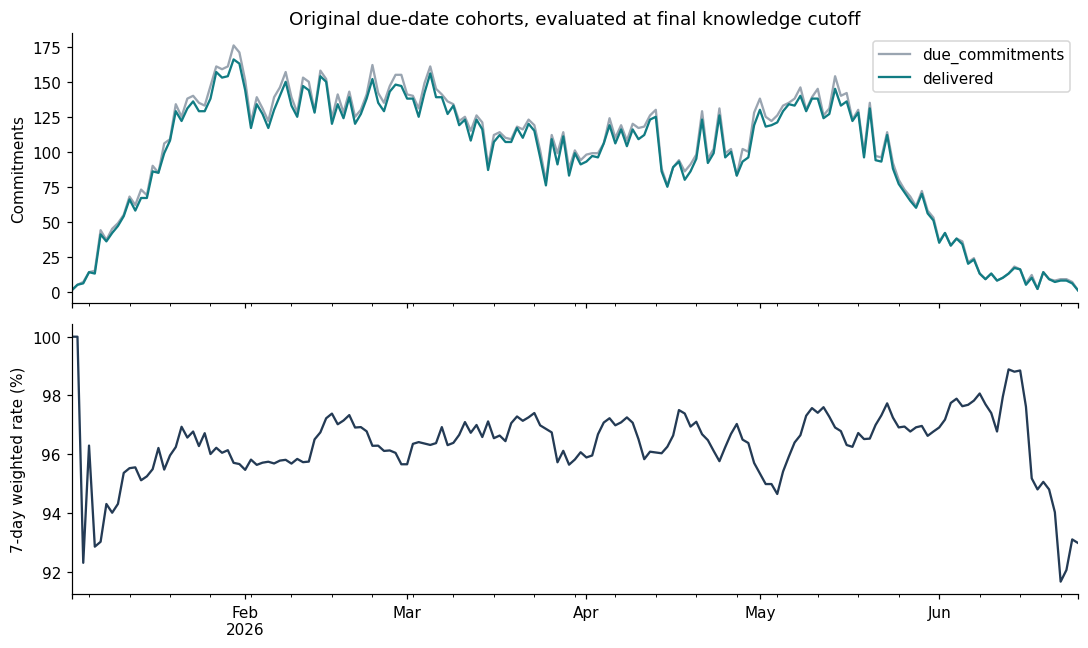

In [8]:
trend=pd.read_csv(REPORTS/'delivery_trend.csv',parse_dates=['due_date']).set_index('due_date')
trend=trend.reindex(pd.date_range(trend.index.min(),trend.index.max(),freq='D'),fill_value=0)
trend['weighted_7day_delivery_rate']=trend.delivered.rolling(7,min_periods=1).sum()/trend.due_commitments.rolling(7,min_periods=1).sum().replace(0,np.nan)
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
trend[['due_commitments','delivered']].plot(ax=axes[0],color=['#9AA5B1','#117C83']);axes[0].set_ylabel('Commitments')
(trend.weighted_7day_delivery_rate*100).plot(ax=axes[1],color='#243B55');axes[1].set_ylabel('7-day weighted rate (%)')
axes[0].set_title('Original due-date cohorts, evaluated at final knowledge cutoff');plt.tight_layout();plt.show()

## Campaign pacing and cohort analysis

Pacing compares actual qualifying delivery against contracted units already due. It is not a forecast, audience-delivery estimate or customer-retention metric.

In [9]:
campaign=pd.read_csv(REPORTS/'campaign_delivery.csv')
campaign.sort_values(['delivery_rate','due_commitments'],ascending=[True,False]).head(15)

     campaign_id  advertiser_id  ...  delivered_commitments  delivery_rate
38            39              9  ...                    139       0.908497
32            33              3  ...                    141       0.909677
10            11             11  ...                    122       0.910448
107          108             18  ...                    112       0.910569
25            26             26  ...                    137       0.913333
111          112             22  ...                    141       0.927632
0              1              1  ...                    129       0.928058
62            63              3  ...                    142       0.928105
66            67              7  ...                    136       0.931507
73            74             14  ...                    137       0.931973
50            51             21  ...                    140       0.933333
106          107             17  ...                    126       0.933333
28            29         

In [10]:
cohorts=pd.read_csv(REPORTS/'campaign_start_cohorts.csv')
cohorts

  campaign_start_month  due_commitments  delivered  delivery_rate
0              2026-01             5589       5378       0.962247
1              2026-02             3197       3079       0.963090
2              2026-03             3191       3086       0.967095
3              2026-04             3902       3765       0.964890
4              2026-05             1559       1509       0.967928

In [11]:
durations=due.groupby('duration_seconds').agg(due_commitments=('commitment_id','size'),original_delivered=('original_delivered','sum'),delivered=('delivered','sum'))
durations['original_failure_rate']=1-durations.original_delivered/durations.due_commitments
durations

                  due_commitments  ...  original_failure_rate
duration_seconds                   ...                       
30                          14118  ...               0.070973
60                           3320  ...               0.107229

[2 rows x 4 columns]

## Operational recommendation

Prioritize mature unconfirmed commitments using campaign deadline, station evidence and replacement status. Keep awaiting-log items provisional and review segment uncertainty before changing delivery allocation.